# Tema 21 · Texto como datos: tokens, vocabulario y clasificación

Convertir palabras en números y clasificar textos con lo que ya sabes.

Este cuaderno es el tema 21 de la [ruta de aprendizaje de la OBIA](https://iabolivia.org/aprende/aprendizaje-automatico/): la teoría y los ejercicios de [la página del tema](https://iabolivia.org/aprende/aprendizaje-automatico/21-texto-como-datos-tokens-vocabulario-y-clasificacion/), con todo su código. Ejecuta las celdas en orden, de arriba abajo (o *Entorno de ejecución → Ejecutar todas*).

Debajo de cada celda está la salida que dio cuando se escribió el tema. Al ejecutarla, la tuya puede variar en los últimos decimales. Las actividades interactivas están en la página del tema.

Este tema entrena o usa redes grandes: en Colab, *Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU* lo hace mucho más rápido.

Primero, las bibliotecas que este tema necesita y que Colab no trae (o trae en otra versión):

In [ ]:
!pip install -q accelerate==1.15.0 datasets==5.1.0 transformers==5.21.0

# Teoría

## La pregunta

Una tienda en línea recibe miles de reseñas por día: «Me encantó, llegó rápido», «Se rompió a la semana, no lo compren». Quieren separar automáticamente las contentas de las enojadas. En el tema 8 aprendiste a clasificar con regresión logística, pero la logística solo sabe multiplicar **números** por pesos. Una reseña no es una tabla de números: es una fila de letras de largo variable.

¿Cómo se convierte un texto en números que un modelo pueda usar? Esa es la pregunta de este tema, y la respuesta tiene varias capas: cortar el texto en pedazos (**tokens**), darle un número a cada pedazo (el **vocabulario**), y después contar, ponderar o rellenar esos números según lo que el modelo necesite. Todo lo que viene en la ruta (embeddings, transformers, los modelos de lenguaje grandes) empieza exactamente aquí.

En este tema vas a:

- **normalizar** un texto y partirlo en tokens por palabras, por caracteres y por **subpalabras** con un BPE programado por ti;
- construir un **vocabulario** con un token para las palabras desconocidas, `<UNK>`;
- ver la **ley de Zipf** en un libro entero: pocas palabras lo llenan casi todo;
- comparar tu tokenizador con los de GPT-2 y DistilBERT;
- construir un **modelo de lenguaje de n-gramas** y medirlo con la **perplejidad**;
- representar textos con **bolsa de palabras** y **TF-IDF**, programar un clasificador **Naive Bayes** y compararlo con la regresión logística para clasificar reseñas;
- armar lotes de frases de distinto largo con **padding** y **máscara**.

Necesitas lo del tema 2 (diccionarios y contar palabras), el tema 5 (la regla de Bayes y los logaritmos), el tema 8 (regresión logística), el tema 9 (exactitud y matriz de confusión), el tema 10 (pipelines) y el tema 18 (tensores de PyTorch).

## Actividad: taller de tokens

Escribe una frase en español. El taller la parte de tres maneras: en **palabras**, en **caracteres** y con **BPE**, un método que aprende pedazos de palabras a partir de un texto. Este BPE se entrenó en tu navegador con el comienzo del *Quijote* («En un lugar de la Mancha…»). El deslizador elige cuántas **fusiones** usa: cada fusión junta los dos pedazos vecinos que más se repiten en ese texto y crea un token nuevo. El token que creó la última fusión aparece con borde coral si está en tu frase. El «_» marca el final de una palabra.

Abajo ves la **bolsa de palabras** de tus dos frases (cuántas veces aparece cada palabra en cada una) y el **lote**: las dos frases como listas de números, rellenadas con ceros para que tengan el mismo largo, con su **máscara**.

> **Actividad interactiva:** está en la [página del tema](https://iabolivia.org/aprende/aprendizaje-automatico/21-texto-como-datos-tokens-vocabulario-y-clasificacion/teoria/). Ábrela en el navegador para usarla.
Prueba esto, en orden:

1. Pon las fusiones en 0. ¿En qué se parecen los tokens de BPE a los caracteres? ¿En qué se diferencian?
2. Sube las fusiones de a poco y mira «Últimas fusiones aprendidas». ¿Qué pedazos aparecen primero? ¿Te suenan a terminaciones del español?
3. Con 150 fusiones, ¿cuántos tokens tiene la frase? ¿Y el vocabulario? Anota los dos números con 0, 50 y 150 fusiones.
4. Escribe una palabra que no esté en el texto de entrenamiento, como «computadora». ¿Cómo la parte el BPE? Ahora escribe «kiwi»: la *k* y la *w* nunca aparecieron en ese texto, así que quedan como desconocidas (con borde punteado) y su número en el lote es 1, el de `<unk>` (el mismo token desconocido que más abajo escribimos `<UNK>`).
5. Escribe en la frase 2 las mismas palabras de la frase 1, pero en otro orden. ¿Cambia la bolsa de palabras?
6. Alarga o acorta la frase 2. ¿Qué le pasa al relleno y a la máscara?

La idea central: **con más fusiones, cada frase se parte en menos tokens, pero el vocabulario crece**. Palabras y caracteres son los dos extremos de esa balanza, y BPE te deja elegir un punto intermedio.

## El texto: *Don Quijote*

Para estudiar cómo se comportan las palabras necesitamos mucho texto. Usaremos *El ingenioso hidalgo don Quijote de la Mancha*, de Miguel de Cervantes, que es de dominio público. Lo descargamos del [Proyecto Gutenberg](https://www.gutenberg.org/ebooks/2000) (libro n.º 2000) una sola vez. Gutenberg pone al principio y al final del archivo una cabecera y un pie en inglés con su licencia; el libro está entre dos marcas, así que cortamos ahí. Por favor, no automatices descargas masivas de Gutenberg: una descarga y guardarla, como aquí, es lo correcto.

In [ ]:
import re
import urllib.request
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

# Don Quijote en el Proyecto Gutenberg (libro n.º 2000, dominio público).
# Se baja una sola vez y queda guardado en la carpeta «datos».
URL = "https://www.gutenberg.org/cache/epub/2000/pg2000.txt"
archivo = Path("datos/quijote-pg2000.txt")
if not archivo.exists():
    archivo.parent.mkdir(exist_ok=True)
    urllib.request.urlretrieve(URL, archivo)

crudo = archivo.read_text(encoding="utf-8")
# El libro está entre dos marcas: se quitan la cabecera y el pie
marca = crudo.index("*** START OF THE PROJECT GUTENBERG EBOOK")
inicio = crudo.index("\n", marca) + 1
fin = crudo.index("*** END OF")
quijote = crudo[inicio:fin].strip()

print(f"{len(crudo):,} caracteres con cabecera y pie")
print(f"{len(quijote):,} caracteres del libro")
k = quijote.index("En un lugar de la Mancha")
print(quijote[k:k + 70].replace("\n", " "))

2,130,057 caracteres con cabecera y pie
2,110,726 caracteres del libro
En un lugar de la Mancha, de cuyo nombre no quiero acordarme, no ha mu


Más de dos millones de caracteres: es un libro largo. Para la computadora, `quijote` es por ahora una sola cadena de texto, y nuestro trabajo es partirla.

## Normalizar y partir en palabras

La forma más natural de partir un texto es en **palabras**. Antes conviene **normalizar**: decidir qué diferencias no importan. En el tema 2 pasaste todo a minúsculas y quitaste la puntuación, para que «Pan», «pan,» y «pan» contaran como lo mismo. Ahora lo hacemos con una **expresión regular**: `\w+` significa «una o más letras o números seguidos». En Python, `\w` reconoce también las letras con tilde y la ñ, así que «mañana» queda entera.

In [ ]:
def palabras(texto):
    """Pasa a minúsculas y devuelve la lista de palabras."""
    return re.findall(r"\w+", texto.lower())

todas = palabras(quijote)
conteo = Counter(todas)
print(f"{len(todas):,} palabras, {len(conteo):,} distintas")
print(conteo.most_common(5))

383,640 palabras, 22,950 distintas
[('que', 20769), ('de', 18410), ('y', 18272), ('la', 10492), ('a', 9876)]


Cada pedazo en que partimos el texto se llama **token**, y el proceso, **tokenización**. Aquí los tokens son palabras: hay 383 640 en el libro, pero solo 22 950 distintas. El `Counter` del módulo `collections` es el diccionario palabra → cuenta del tema 2, ya hecho.

### ¿Quitar las tildes?

Otra normalización posible es quitar las tildes. En inglés casi no hay, pero en español una tilde puede cambiar la palabra:

In [ ]:
def sin_tildes(palabra):
    """Quita las tildes (pero no la ñ)."""
    return palabra.translate(str.maketrans("áéíóúü", "aeiouu"))

conteo_sin = Counter(sin_tildes(p) for p in todas)
print(f"Distintas con tildes: {len(conteo):,}   sin tildes: "
      f"{len(conteo_sin):,}")
for a, b in [("el", "él"), ("si", "sí"), ("mas", "más"),
             ("esta", "está")]:
    print(f"{a:<5} {conteo[a]:>5} veces   {b:<5} {conteo[b]:>5} veces")

Distintas con tildes: 22,950   sin tildes: 22,504
el     8265 veces   él     1282 veces
si     1968 veces   sí      346 veces
mas     240 veces   más    2055 veces
esta    631 veces   está    442 veces


Sin tildes se pierden 446 palabras distintas: algunas eran la misma palabra mal escrita, pero otras eran palabras diferentes que ahora se confunden. «El» es un artículo y «él» un pronombre; «si» es condicional y «sí» afirma; «más» es cantidad y «mas» (en el castellano del Quijote) significa «pero». Por eso, en español, **las tildes casi siempre se quedan**. Se quitan solo cuando el texto viene muy mal escrito (por ejemplo, mensajes de chat sin tildes) y es más importante juntar variantes que distinguir significados. Como verás más abajo, algunos tokenizadores famosos las quitan sin preguntar.

## La ley de Zipf

¿Qué tan repartidas están las palabras? Ordenemos las 22 950 de la más frecuente a la menos frecuente y grafiquemos cuántas veces aparece cada una frente a su puesto, su **rango**:

Las 10 más frecuentes cubren el 29% del texto
Las 100 más frecuentes cubren el 55% del texto
Aparecen una sola vez: 11,158 palabras (49% del vocabulario)


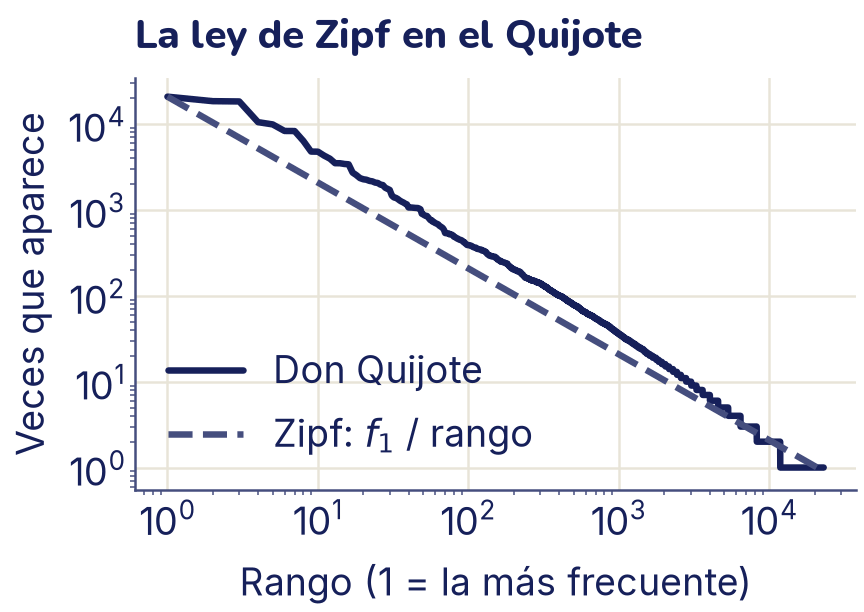

In [ ]:
frecuencias = np.array(sorted(conteo.values(), reverse=True))
rangos = np.arange(1, len(frecuencias) + 1)

print("Las 10 más frecuentes cubren el "
      f"{frecuencias[:10].sum() / len(todas):.0%} del texto")
print("Las 100 más frecuentes cubren el "
      f"{frecuencias[:100].sum() / len(todas):.0%} del texto")
una_vez = (frecuencias == 1).sum()
print(f"Aparecen una sola vez: {una_vez:,} palabras "
      f"({una_vez / len(conteo):.0%} del vocabulario)")

plt.loglog(rangos, frecuencias, color="C0", label="Don Quijote")
plt.loglog(rangos, frecuencias[0] / rangos, color="C2",
           linestyle="--", label="Zipf: $f_1$ / rango")
plt.xlabel("Rango (1 = la más frecuente)")
plt.ylabel("Veces que aparece")
plt.title("La ley de Zipf en el Quijote")
plt.legend()
plt.show()

En escala logarítmica la curva es casi una recta: la palabra del puesto 10 aparece más o menos la décima parte de veces que la primera, y la del puesto 100, la centésima parte. Es la **ley de Zipf**, y se cumple de forma parecida en casi cualquier idioma y cualquier texto largo. Tiene dos consecuencias prácticas:

- **Unas pocas palabras llenan casi todo.** Las 10 más frecuentes («que», «de», «y», «la»…) son el 29 % del texto, y las 100 primeras, más de la mitad. Casi no dicen nada del tema del texto: por eso más adelante TF-IDF les baja el peso.
- **Hay una cola larguísima de palabras raras.** Casi la mitad de las palabras distintas (11 158) aparecen **una sola vez**. Por más texto que juntes, siempre aparecerán palabras nuevas.

## El vocabulario y el token desconocido

Un modelo no trabaja con palabras sino con **números**. El **vocabulario** es el diccionario que le da a cada token un número entero, su **ID**. Como hay palabras rarísimas, se suele dejar fuera a las que aparecen muy poco y reemplazarlas por un token especial, `<UNK>` (de *unknown*, desconocido). Así el vocabulario es más chico y el modelo no tiene que aprender algo de palabras que vio una sola vez. Reservamos también el número 0 para `<PAD>`, el relleno, que usaremos al final.

In [ ]:
def construir_vocabulario(conteo, minimo=2):
    """Diccionario palabra -> número, con las palabras frecuentes."""
    vocab = {"<PAD>": 0, "<UNK>": 1}
    for palabra, n in conteo.most_common():
        if n >= minimo:
            vocab[palabra] = len(vocab)
    return vocab

def codificar(tokens, vocab):
    """Cambia cada token por su número; los desconocidos, por <UNK>."""
    return [vocab.get(t, vocab["<UNK>"]) for t in tokens]

vocab = construir_vocabulario(conteo)
print(f"Vocabulario: {len(vocab):,} tokens")
frase = "Don Quijote vio un dinosaurio en la computadora"
ids = codificar(palabras(frase), vocab)
print(palabras(frase))
print(ids)

Vocabulario: 11,794 tokens
['don', 'quijote', 'vio', 'un', 'dinosaurio', 'en', 'la', 'computadora']
[18, 22, 166, 28, 1, 7, 5, 1]


Dejando solo las palabras que aparecen al menos dos veces, el vocabulario baja de casi 23 000 a 11 794 tokens. «Dinosaurio» y «computadora» no están en el Quijote: las dos reciben el número 1, el de `<UNK>`. Para el modelo, ambas son la misma palabra desconocida. Ese es el problema de tokenizar por palabras: **toda palabra nueva se pierde**, y en español, con tantas conjugaciones («comí», «comieron», «comeríamos»), aparecen palabras nuevas todo el tiempo.

## Caracteres: el otro extremo

El remedio opuesto es partir en **caracteres**. El vocabulario es diminuto y nunca hay desconocidos (salvo símbolos rarísimos):

In [ ]:
letras = sorted(set(quijote.lower()))
print(f"Caracteres distintos: {len(letras)}")
print("".join(letras[22:]))
print(len(palabras(frase)), "palabras y", len(frase), "caracteres")

Caracteres distintos: 62
abcdefghijlmnopqrstuvwxyz¡«»¿àáéíïñóùúü—
8 palabras y 47 caracteres


Con solo 62 caracteres distintos (letras, tildes, números y signos) se puede escribir cualquier palabra del libro, incluso las que todavía no existen. El precio: la misma frase pasa de 8 tokens a 47. Las secuencias se vuelven mucho más largas, y cada token, por sí solo, casi no significa nada: una «e» puede estar en cualquier palabra.

## Subpalabras: BPE

Entre palabras y caracteres hay un punto intermedio: **subpalabras**. La idea de **BPE** (*byte pair encoding*, codificación por pares) es empezar con caracteres e ir juntando los pares que más se repiten:

1. Parte cada palabra en caracteres y agrega un «_» al final, para saber dónde termina.
2. Cuenta todos los pares de piezas vecinas en todo el texto.
3. Junta el par más frecuente en una pieza nueva (una **fusión**) y anótala.
4. Repite los pasos 2 y 3 tantas veces como fusiones quieras.

Las palabras frecuentes terminan siendo un solo token; las raras quedan partidas en pedazos conocidos. Así no hay palabras desconocidas y las secuencias no son tan largas. Este es el BPE completo, en Python puro. Para ir rápido, no recorre el texto entero en cada paso: trabaja con el conteo de palabras distintas, y cada par vale tantas veces como aparece su palabra.

In [ ]:
def contar_pares(partes):
    """Cuántas veces aparece cada par de piezas vecinas."""
    pares = Counter()
    for piezas, n in partes.items():
        for par in zip(piezas, piezas[1:]):
            pares[par] += n
    return pares

def fusionar(piezas, par):
    """Junta en una sola pieza cada aparición del par."""
    nuevas, i = [], 0
    while i < len(piezas):
        if i + 1 < len(piezas) and (piezas[i], piezas[i + 1]) == par:
            nuevas.append(piezas[i] + piezas[i + 1])
            i += 2
        else:
            nuevas.append(piezas[i])
            i += 1
    return tuple(nuevas)

def entrenar_bpe(conteo, n_fusiones):
    """Aprende las fusiones de BPE a partir de un conteo de palabras."""
    # Cada palabra empieza partida en letras, con «_» al final
    partes = {tuple(p) + ("_",): n for p, n in conteo.items()}
    fusiones, tokens = [], []
    for _ in range(n_fusiones):
        pares = contar_pares(partes)
        if not pares:
            break
        mejor = max(pares, key=pares.get)       # el par más frecuente
        fusiones.append(mejor)
        partes = {fusionar(p, mejor): n for p, n in partes.items()}
        tokens.append(sum(len(p) * n for p, n in partes.items()))
    return fusiones, tokens

def tokenizar_bpe(palabra, fusiones):
    """Parte una palabra aplicando las fusiones en el orden aprendido."""
    piezas = tuple(palabra) + ("_",)
    for par in fusiones:
        piezas = fusionar(piezas, par)
    return list(piezas)

`entrenar_bpe` devuelve la lista de fusiones en orden, y además, después de cada fusión, cuántos tokens tendría todo el libro. Entrenemos 300 fusiones con el conteo del Quijote (tarda unos segundos):

In [ ]:
fusiones, tokens_bpe = entrenar_bpe(conteo, 300)
print("Primeras fusiones:")
print(["".join(par) for par in fusiones[:12]])
for p in ["quijote", "molinos", "computadora", "boliviano"]:
    print(f"{p:>12} -> {tokenizar_bpe(p, fusiones)}")

Primeras fusiones:
['e_', 'a_', 'o_', 's_', 'n_', 'qu', 'er', 'que_', 'es', 'en', 'de_', 'os_']
     quijote -> ['quijote_']
     molinos -> ['m', 'ol', 'in', 'os_']
 computadora -> ['com', 'pu', 't', 'ad', 'ora_']
   boliviano -> ['b', 'o', 'li', 'vi', 'an', 'o_']


Las primeras fusiones son terminaciones: «e_», «a_», «o_», «s_» son letras al final de una palabra. Después llegan «qu», «que_» (la palabra más frecuente), «de_» y «os_», el plural masculino. Nadie le enseñó gramática al algoritmo: las encontró contando. «Quijote» aparece tantas veces que se volvió un solo token. «Computadora» y «boliviano» nunca aparecen en el libro, pero el BPE las arma con pedazos que sí conoce, sin perderlas como `<UNK>`.

¿Cuánto se acorta el texto con cada fusión? `tokens_bpe` lo anotó:

Sin fusiones: 5.30 tokens por palabra
Con 300: 2.08 tokens por palabra


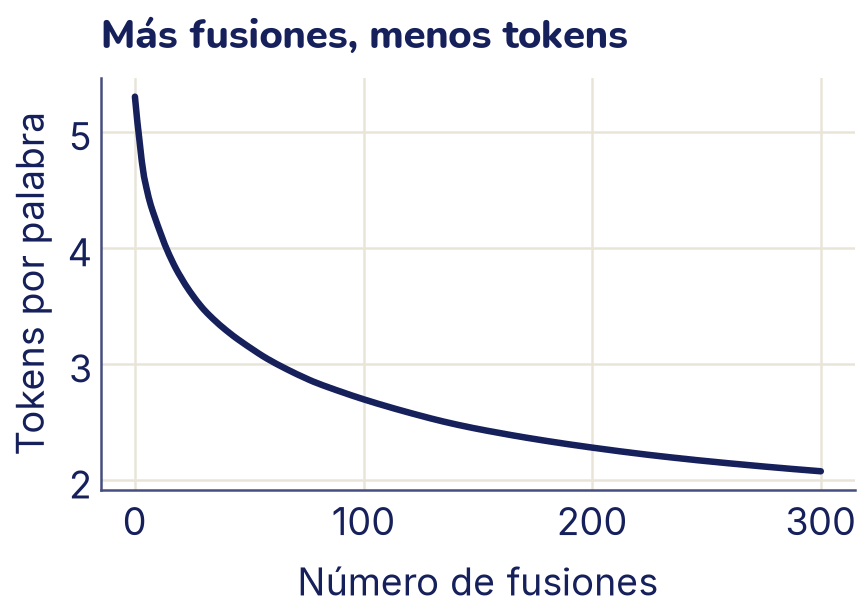

In [ ]:
letras_texto = sum(len(p) + 1 for p in todas)    # letras más el «_»
por_palabra = np.array([letras_texto] + tokens_bpe) / len(todas)
print(f"Sin fusiones: {por_palabra[0]:.2f} tokens por palabra")
print(f"Con 300: {por_palabra[-1]:.2f} tokens por palabra")

plt.plot(range(len(por_palabra)), por_palabra, color="C0")
plt.xlabel("Número de fusiones")
plt.ylabel("Tokens por palabra")
plt.title("Más fusiones, menos tokens")
plt.show()

Sin fusiones, cada palabra ocupa 5,3 tokens (sus letras más el «_»). Las primeras fusiones acortan mucho el texto porque juntan los pares más comunes; las siguientes ayudan cada vez menos. Cada fusión agrega un token al vocabulario: es la misma balanza de la actividad. Los tokenizadores de los modelos reales hacen decenas de miles de fusiones sobre textos enormes.

## Tokenizadores de verdad

Los modelos de lenguaje traen su propio tokenizador, entrenado junto con el modelo. **Hugging Face** es un sitio que reúne miles de modelos y datasets públicos; cada uno tiene un nombre de la forma «usuario/modelo», como `openai-community/gpt2`. Su librería `transformers` los carga con `from_pretrained`, que la primera vez los descarga de internet y los guarda en la computadora, y las siguientes los lee de ahí. Los tokenizadores se cargan con `AutoTokenizer`.

En Colab, `transformers` ya viene instalada, pero puede ser una versión anterior a la 5, que es la que usa esta ruta desde aquí hasta el tema 25. En una celda aparte, al principio del cuaderno, ejecuta `!pip install -U "transformers>=5"` (`-U` actualiza lo que ya está instalado). Si ya habías importado `transformers`, reinicia la sesión del cuaderno. Para ver qué versión tienes: `import transformers` y `print(transformers.__version__)`. Comparemos dos: el de **GPT-2** (un BPE; licencia MIT) y el de **DistilBERT** (WordPiece, una variante parecida; licencia Apache-2.0). Solo se descarga el tokenizador, que pesa menos de 2 MB.

In [ ]:
from transformers import AutoTokenizer

tok_gpt2 = AutoTokenizer.from_pretrained("openai-community/gpt2")
tok_bert = AutoTokenizer.from_pretrained(
    "distilbert/distilbert-base-uncased")
print(f"Vocabulario de GPT-2: {len(tok_gpt2):,}   "
      f"de DistilBERT: {len(tok_bert):,}")

es = "Mañana iré a la panadería con mi hermano."
print(" ".join(tok_gpt2.tokenize(es)))
print(" ".join(tok_bert.tokenize(es)))
ids = tok_gpt2(es)["input_ids"]
print(ids[:6])
print([tok_gpt2.decode([i]) for i in ids[:6]])

Vocabulario de GPT-2: 50,257   de DistilBERT: 30,522
Ma Ã± ana Ġir Ã© Ġa Ġla Ġpan ader ÃŃa Ġcon Ġmi Ġher man o .
mana ##na ir ##e a la pan ##ade ##ria con mi herman ##o .
[21467, 12654, 2271, 4173, 2634, 257]
['Ma', 'ñ', 'ana', ' ir', 'é', ' a']


Hay mucho que leer en esas dos líneas:

- **GPT-2** marca con «Ġ» el espacio que va antes de una palabra. Además trabaja con **bytes**, no con letras. La computadora guarda cada carácter como uno o más **bytes** (números de 0 a 255); la forma más común de hacerlo se llama **UTF-8** (la del `encoding="utf-8"` del tema 2). En UTF-8, las letras del inglés ocupan 1 byte, y la «ñ» y las letras con tilde ocupan 2. GPT-2 muestra cada byte por separado, y por eso la «ñ» y la «é» se ven como «Ã±» y «Ã©»: no es un error. Al decodificar cada ID se recupera el texto normal: «Ma», «ñ», «ana». Gracias a los bytes, GPT-2 nunca tiene un token desconocido.
- **DistilBERT** (la versión *uncased*) pasa todo a minúsculas y **quita las tildes**: «mañana» se volvió «mana» + «##na» e «iré», «ir» + «##e». Los «##» marcan un pedazo que continúa la palabra anterior. Para el inglés da lo mismo, pero en español ese tokenizador ya no distingue «él» de «el».
- Los dos se entrenaron sobre todo con texto en inglés, así que parten las palabras españolas en muchos pedazos: «panadería» son tres tokens.

Contemos los tokens de la misma frase en español y su traducción al inglés con los cinco tokenizadores que tenemos:

Palabras     español:   8   inglés:  10
Caracteres   español:  41   inglés:  49
Nuestro BPE  español:  19   inglés:  33
GPT-2        español:  16   inglés:  11
DistilBERT   español:  14   inglés:  11


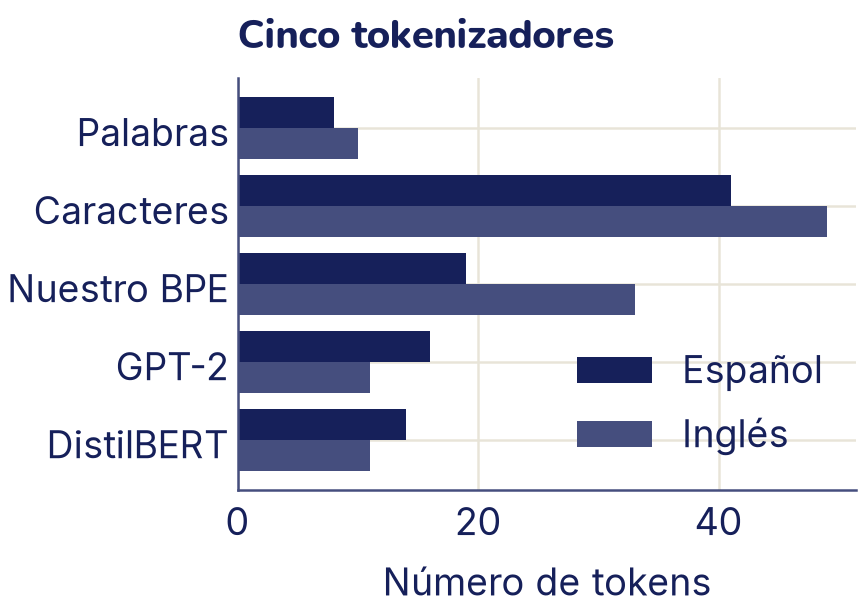

In [ ]:
en = "Tomorrow I will go to the bakery with my brother."
nombres = ["Palabras", "Caracteres", "Nuestro BPE", "GPT-2",
           "DistilBERT"]

def contar_tokens(texto):
    """Cuántos tokens da cada tokenizador para un texto."""
    bpe = sum(len(tokenizar_bpe(p, fusiones)) for p in palabras(texto))
    return [len(palabras(texto)), len(texto), bpe,
            len(tok_gpt2.tokenize(texto)), len(tok_bert.tokenize(texto))]

n_es, n_en = contar_tokens(es), contar_tokens(en)
for nombre, a, b in zip(nombres, n_es, n_en):
    print(f"{nombre:<12} español: {a:>3}   inglés: {b:>3}")

# Solo para dibujar: barras de los dos idiomas, una al lado de la otra
y = np.arange(len(nombres))
plt.barh(y - 0.2, n_es, height=0.4, color="C0", label="Español")
plt.barh(y + 0.2, n_en, height=0.4, color="C2", label="Inglés")
plt.yticks(y, nombres)
plt.gca().invert_yaxis()
plt.xlabel("Número de tokens")
plt.title("Cinco tokenizadores")
plt.legend()
plt.show()

Cada tokenizador funciona mejor en el idioma con que se entrenó. Nuestro BPE, que solo vio el Quijote, parte la frase en inglés en 33 tokens y la española en 19. GPT-2 y DistilBERT, que aprendieron de textos sobre todo en inglés, hacen lo contrario. Esto importa: un modelo tiene un largo máximo de tokens y cobra (en tiempo o en dinero) por token, así que el mismo texto en español le sale más caro.

## Un modelo de lenguaje con n-gramas

Un **modelo de lenguaje** asigna probabilidades a la palabra que viene: después de «don», ¿qué es más probable, «Quijote» o «pescado»? Es la idea detrás de los LLM del tema 24, pero empezamos con la versión más simple: contar.

Un **n-grama** es una secuencia de *n* tokens seguidos. Un modelo de **bigramas** (*n* = 2) estima la probabilidad de una palabra mirando solo la anterior:

$$P ( w \mid v ) \approx \frac{\text{veces que aparece «} v \; w \text{»}}{\text{veces que aparece «} v \text{»}}$$

Para medir el modelo de forma honesta separamos el libro en tres partes, como en el tema 7: entrenamos con el primer 80 %, usamos el 10 % siguiente como **validación** (para comparar modelos y elegir hiperparámetros) y guardamos el último 10 % como **prueba**, para una sola medición final. Las palabras que aparecen menos de dos veces en el entrenamiento pasan a ser `<UNK>`:

In [ ]:
corte_ent = int(0.8 * len(todas))
corte_val = int(0.9 * len(todas))
entren = todas[:corte_ent]
valid = todas[corte_ent:corte_val]
prueba = todas[corte_val:]
vocab_ng = {p for p, n in Counter(entren).items() if n >= 2}

def con_unk(tokens):
    return [t if t in vocab_ng else "<UNK>" for t in tokens]

entren, valid, prueba = con_unk(entren), con_unk(valid), con_unk(prueba)
V = len(vocab_ng) + 1
print(f"Vocabulario: {V:,}   desconocidas en la validación: "
      f"{valid.count('<UNK>') / len(valid):.1%}")

Vocabulario: 10,207   desconocidas en la validación: 6.3%


Hay un problema: muchos bigramas de la validación nunca aparecieron en el entrenamiento, y la fórmula les daría probabilidad 0. Un modelo que dice «imposible» ante algo que sí pasa es infinitamente malo (más abajo verás por qué). La solución que usamos es **mezclar**: la probabilidad final es un 60 % la del bigrama y un 40 % la de la palabra sola (el **unigrama**, que solo cuenta cuántas veces aparece la palabra en todo el entrenamiento). A cada palabra sola le sumamos 1 a su cuenta, para que ninguna quede en cero. Ese 0,6 es un hiperparámetro, `lam` en el código (por λ, lambda).

Por ejemplo, para «quijote» después de «don»: el bigrama da la proporción de veces que a «don» le sigue «quijote», y el unigrama, la proporción de todas las palabras del entrenamiento que son «quijote». La mezcla es 0,6 × bigrama + 0,4 × unigrama:

In [ ]:
def contar_ngramas(tokens, n):
    """Cuenta los n-gramas y sus contextos (los n - 1 tokens de antes)."""
    ngramas = Counter(tuple(tokens[i:i + n])
                      for i in range(len(tokens) - n + 1))
    contextos = Counter()
    for ng, c in ngramas.items():
        contextos[ng[:-1]] += c
    return ngramas, contextos

cuentas = {n: contar_ngramas(entren, n) for n in (1, 2, 3)}

def probabilidad(contexto, palabra, lam=0.6):
    """P(palabra | contexto), mezclando con un contexto más corto."""
    if not contexto:
        ngramas, _ = cuentas[1]
        return (ngramas[(palabra,)] + 1) / (len(entren) + V)
    ngramas, contextos = cuentas[len(contexto) + 1]
    c = contextos[contexto]
    directa = ngramas[contexto + (palabra,)] / c if c else 0
    # Aquí la función se llama a sí misma, con una palabra menos
    return (lam * directa
            + (1 - lam) * probabilidad(contexto[1:], palabra, lam))

ngramas2, contextos2 = cuentas[2]
bigrama = ngramas2[("don", "quijote")] / contextos2[("don",)]
unigrama = probabilidad((), "quijote")
print(f"bigrama {bigrama:.3f}   unigrama {unigrama:.4f}")
print(f"mezcla: {probabilidad(('don',), 'quijote'):.3f}")

bigrama 0.838   unigrama 0.0054
mezcla: 0.505


Después de «don», el bigrama da 0,838: casi siempre viene «quijote». El unigrama da apenas 0,0054, porque «quijote» es una entre muchísimas palabras del libro. La mezcla es 0,6 × 0,838 + 0,4 × 0,0054 ≈ 0,505.

`probabilidad` recibe el contexto como una tupla de palabras: `("don",)` para un bigrama, `()` (vacía) para el unigrama. Fíjate en la última línea de la función: `probabilidad` **se llama a sí misma**, con el contexto una palabra más corto (`contexto[1:]` quita la primera). A eso se le llama **recursión**. Para un bigrama, el contexto `("don",)` se acorta a `()`, y con el contexto vacío la función ya no se llama otra vez: devuelve la probabilidad del unigrama y ahí termina. Para un trigrama pasa lo mismo con un paso más: mezcla con el bigrama, que a su vez mezcla con el unigrama. Así, la misma función sirve para cualquier *n*.

¿Cómo se mide si un modelo de lenguaje es bueno? Con lo **sorprendido** que queda con cada palabra del texto que no vio. Si el modelo le daba a la palabra que vino probabilidad *P*, su **sorpresa** es −ln *P*: vale 0 si estaba seguro (*P* = 1) y crece mientras menos la esperaba. Por ejemplo, si a tres palabras les daba 0,5, 0,1 y 0,01, sus sorpresas son 0,69, 2,30 y 4,61; el promedio es 2,53, y e<sup>2,53</sup> ≈ 12,6. Esa última cuenta, la exponencial del promedio de las sorpresas, es la **perplejidad**:

$$\text{perplejidad} = \mathrm{exp} ( - \frac{1}{N} \sum_{i = 1}^{N} \mathrm{ln} P ( {w}_{i} \mid \text{contexto} ) )$$

Es la entropía cruzada del tema 8, promediada sobre las palabras, con una exponencial al final. Se interpreta así: una perplejidad de 200 significa que el modelo duda, en promedio, como si tuviera que elegir entre 200 palabras igual de probables (en el ejemplo, como entre unas 13). **Más baja es mejor.** Un modelo que no sabe nada y reparte la probabilidad por igual entre las 10 207 palabras tiene perplejidad 10 207. Y si el modelo diera *P* = 0 a una sola palabra que sí aparece, ln 0 = −∞: la sorpresa sería infinita y arruinaría el promedio. Por eso nunca se puede dar probabilidad 0, y por eso mezclamos. En el código, `np.log` es el logaritmo natural, el que en el colegio se escribe ln, y `np.exp(x)` es e<sup>x</sup>.

Comparemos el unigrama y el bigrama en la validación:

In [ ]:
def perplejidad(tokens, n, lam=0.6):
    log_total = 0
    for i in range(n - 1, len(tokens)):
        contexto = tuple(tokens[i - n + 1:i])
        log_total += np.log(probabilidad(contexto, tokens[i], lam))
    return np.exp(-log_total / (len(tokens) - n + 1))

for n in (1, 2):
    print(f"n = {n}: perplejidad {perplejidad(valid, n):.0f}")

n = 1: perplejidad 469
n = 2: perplejidad 210


Mirar solo la palabra anterior baja la perplejidad de 469 a 210: el contexto ayuda muchísimo. Elegimos el bigrama, y recién ahora lo medimos, una sola vez, en la prueba:

In [ ]:
print(f"Bigrama en la prueba: perplejidad {perplejidad(prueba, 2):.0f}")

Bigrama en la prueba: perplejidad 207


En la prueba da 207, casi lo mismo que en la validación: es lo que se puede esperar del modelo con texto que nunca vio.

¿Qué aprendió el modelo? Veamos las palabras más probables después de «don» y de «sancho», contando en el entrenamiento:

In [ ]:
for previa in ["don", "sancho"]:
    siguientes = Counter({ng[1]: c for ng, c in ngramas2.items()
                          if ng[0] == previa})
    total = contextos2[(previa,)]
    print(previa, "->", [(p, round(c / total, 2))
                         for p, c in siguientes.most_common(4)])

don -> [('quijote', 0.84), ('fernando', 0.06), ('luis', 0.02), ('diego', 0.01)]
sancho -> [('que', 0.14), ('panza', 0.13), ('y', 0.08), ('dijo', 0.05)]


Después de «don», el 84 % de las veces viene «quijote». Después de «sancho», «que» (14 %) y «panza» (13 %) casi empatan: mirando una sola palabra, el modelo no sabe si viene el apellido o el resto de la frase. Con estas probabilidades el modelo puede **generar** texto: se elige la siguiente palabra al azar según sus probabilidades, se agrega, y se repite.

In [ ]:
rng = np.random.default_rng(0)
texto = ["dijo"]
for _ in range(14):
    siguientes = [(ng[1], c) for ng, c in ngramas2.items()
                  if ng[0] == texto[-1]]
    opciones = [p for p, c in siguientes]
    pesos = np.array([c for p, c in siguientes], dtype=float)
    texto.append(rng.choice(opciones, p=pesos / pesos.sum()))
print(" ".join(texto))

dijo sancho y de la dura la tenía las espaldas subamos donde se quiebre pues


Cada par de palabras vecinas tiene sentido, pero la frase entera no: el modelo solo recuerda una palabra hacia atrás. En el ejercicio 4 vas a probar con trigramas y verás por qué recordar más no es tan fácil con un solo libro. Los modelos del tema 24 resuelven ese problema con redes neuronales y la atención del tema 23.

## Bolsa de palabras y TF-IDF

Volvamos a la pregunta del principio: clasificar textos. La regresión logística necesita que cada texto sea **un vector del mismo largo**, pero los textos tienen largos distintos. La **bolsa de palabras** resuelve esto así: una columna por cada palabra del vocabulario, y en cada fila, cuántas veces aparece esa palabra en ese texto. El orden se pierde; es como vaciar las palabras en una bolsa y contarlas. `CountVectorizer` de scikit-learn lo hace en una línea (también pasa a minúsculas y parte en palabras por su cuenta):

In [ ]:
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer

frases = ["el perro come pan",
          "el gato come pescado",
          "el perro y el gato duermen"]
bolsa = CountVectorizer()
X_bolsa = bolsa.fit_transform(frases)
print(pd.DataFrame(X_bolsa.toarray(),
                   columns=bolsa.get_feature_names_out()))

   come  duermen  el  gato  pan  perro  pescado
0     1        0   1     0    1      1        0
1     1        0   1     1    0      0        1
2     0        1   2     1    0      1        0


Cada frase es ahora una fila de 7 números. En un **corpus** (una colección grande de textos) real hay miles de columnas, casi todas en cero para cada texto; scikit-learn guarda esas tablas en un formato **disperso** (*sparse*) que solo anota los valores que no son cero, y `toarray()` las convierte en una tabla normal para mirarlas.

El problema de contar es que «el» aparece en todas las frases y pesa tanto como «pescado», que es mucho más informativa. **TF-IDF** corrige eso: multiplica la frecuencia de la palabra en el texto (**TF**, *term frequency*) por un factor que es mayor cuanto **menos** documentos la contienen (**IDF**, *inverse document frequency*). Con *n* documentos, de los cuales df(*t*) contienen la palabra *t*, scikit-learn usa:

$$\text{idf} ( t ) = \mathrm{ln} \frac{1 + n}{1 + \text{df} ( t )} + 1$$

Después divide cada fila por su **norma** (la longitud del vector, √(suma de cuadrados), del tema 3), para que todas midan 1 y un texto largo no gane solo por tener más palabras.

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer()
X_tfidf = tfidf.fit_transform(frases)
print(pd.DataFrame(X_tfidf.toarray(),
                   columns=tfidf.get_feature_names_out()).round(2))

   come  duermen    el  gato   pan  perro  pescado
0  0.48     0.00  0.37  0.00  0.63   0.48     0.00
1  0.48     0.00  0.37  0.48  0.00   0.00     0.63
2  0.00     0.53  0.63  0.40  0.00   0.40     0.00


En la primera frase las cuatro palabras aparecen una vez, pero no pesan lo mismo: «pan», que está en un solo documento, pesa 0,63; «come» y «perro», que están en dos, 0,48; y «el», que está en los tres, 0,37. En la tercera, «el» aparece dos veces y pesa 0,63, apenas más que «duermen» (0,53), que aparece una sola vez pero solo en esa frase.

## Naive Bayes: contar palabras con la regla de Bayes

Antes de llevar estos vectores a la regresión logística, probemos un clasificador que no necesita descenso de gradiente: solo **cuenta**. Se llama **Naive Bayes** (en español, Bayes ingenuo) y es la regla de Bayes del tema 5 aplicada a palabras.

Queremos P(positiva | texto): la probabilidad de que una reseña sea positiva sabiendo qué palabras tiene. La regla de Bayes la calcula a partir de la probabilidad «al revés», la del texto sabiendo la clase:

$$P ( \text{clase} \mid \text{texto} ) = \frac{P ( \text{texto} \mid \text{clase} ) \cdot P ( \text{clase} )}{P ( \text{texto} )}$$

- P(clase) es la **probabilidad previa** (en inglés, *prior*): qué fracción de los textos de entrenamiento es de esa clase.
- P(texto | clase) dice qué tan probable es ese texto entre los textos de esa clase.
- P(texto) es el mismo número para las dos clases. Para saber cuál gana basta comparar los numeradores; si queremos probabilidades, al final se divide cada numerador entre la suma de los dos, para que sumen 1.

El problema es P(texto | clase): esa reseña exacta casi seguro nunca apareció en el entrenamiento, así que no se puede contar. Aquí entra la suposición **ingenua**: dentro de cada clase, cada palabra aparece **independiente** de las demás. Entonces la probabilidad del texto es el producto de las probabilidades de sus palabras: P(«buena comida» | positiva) ≈ P(buena | positiva) · P(comida | positiva). La suposición es falsa (*waste* y *money* suelen ir juntas, y *not* cambia el sentido de la palabra que le sigue), pero para decidir entre dos clases funciona sorprendentemente bien. Como en la bolsa de palabras, el orden no importa: Naive Bayes usa justamente las cuentas de `CountVectorizer`.

P(palabra | clase) sí se puede contar: de todas las palabras de los textos de esa clase, qué fracción es esa palabra. Pero si una palabra nunca apareció en una clase, su probabilidad sería 0, y un solo 0 en el producto anula el texto entero. Es el mismo problema del modelo de n-gramas, y la solución es la que usamos ahí con el unigrama: sumar 1 a cada cuenta, y sumar *V* (el tamaño del vocabulario) al total, para que las probabilidades de todas las palabras sigan sumando 1. Ese «sumar 1» se llama **suavizado de Laplace**:

$$P ( w \mid c ) = \frac{\text{cuenta} ( w , c ) + 1}{\text{total} ( c ) + V}$$

Aquí cuenta(*w*, *c*) es cuántas veces aparece la palabra *w* en todos los textos de la clase *c*, y total(*c*) cuántas palabras tienen esos textos en total.

Falta un detalle. Un texto largo multiplica cientos de probabilidades pequeñas, y el producto se vuelve tan chico que la computadora lo redondea a 0 (lo viste en el tema 5). Por eso se trabaja con logaritmos, que convierten el producto en una suma. El **puntaje** de cada clase es:

$$\text{puntaje} ( c ) = \mathrm{ln} P ( c ) + \sum_{w} {x}_{w} \cdot \mathrm{ln} P ( w \mid c )$$

donde *x*<sub>*w*</sub> es cuántas veces aparece la palabra *w* en el texto, es decir, la fila del texto en la bolsa de palabras: una palabra que aparece dos veces suma dos veces. Gana la clase con el puntaje más alto.

Probémoslo con seis opiniones cortas de un restaurante, escritas para este ejemplo: tres positivas (1) y tres negativas (0). Con la bolsa de palabras en una matriz `X` (una fila por texto) y las clases en `y`, entrenar es contar:

In [ ]:
mini = ["muy buena la comida", "buena atención y buena comida",
        "excelente lugar, muy limpio", "comida fría y mala atención",
        "muy caro y sucio", "mala comida, nunca más"]
y_mini = np.array([1, 1, 1, 0, 0, 0])
cv_mini = CountVectorizer()
X_mini = cv_mini.fit_transform(mini).toarray()

def entrenar_nb(X, y, alpha=1):
    """Devuelve ln P(clase) y ln P(palabra | clase) para las clases 0 y 1."""
    # (y == c) vale 1 en las filas de la clase c y 0 en las demás: el
    # producto X.T @ (y == c) suma la columna de cada palabra en esas filas
    cuentas = np.array([X.T @ (y == c) for c in (0, 1)])
    # keepdims=True deja el resultado como columna, de forma (2, 1)
    totales = cuentas.sum(axis=1, keepdims=True)
    log_p_palabra = np.log((cuentas + alpha)
                           / (totales + alpha * X.shape[1]))
    # np.bincount(y) cuenta cuántas veces aparece 0, 1, ... en y
    log_prior = np.log(np.bincount(y) / len(y))
    return log_prior, log_p_palabra

def puntajes_nb(X, log_prior, log_p_palabra):
    """Una fila por texto y una columna por clase."""
    return log_prior + X @ log_p_palabra.T

prior_mini, log_p_mini = entrenar_nb(X_mini, y_mini)
print("Vocabulario:", X_mini.shape[1], "palabras")
for p in ["buena", "mala", "caro", "comida"]:
    neg, pos = np.exp(log_p_mini[:, cv_mini.vocabulary_[p]])
    print(f"{p:<7} P(· | negativa) = {neg:.3f}   "
          f"P(· | positiva) = {pos:.3f}")

Vocabulario: 14 palabras
buena   P(· | negativa) = 0.040   P(· | positiva) = 0.154
mala    P(· | negativa) = 0.120   P(· | positiva) = 0.038
caro    P(· | negativa) = 0.080   P(· | positiva) = 0.038
comida  P(· | negativa) = 0.120   P(· | positiva) = 0.115


`alpha` es lo que se suma a cada cuenta: con `alpha=1`, el suavizado de Laplace. Como en el tema 5, `np.log` es el logaritmo natural, ln, y `np.exp` lo deshace. `CountVectorizer` ignora las palabras de una sola letra, como «y», así que las tres negativas suman 11 palabras y las tres positivas 12. «buena» aparece 3 veces en las positivas: (3 + 1)/(12 + 14) ≈ 0,154. En las negativas no aparece nunca, pero gracias al suavizado no queda en 0: (0 + 1)/(11 + 14) = 0,04. «comida», que está en los dos lados, tiene casi la misma probabilidad en ambos: no ayuda a decidir.

Ahora clasifiquemos una opinión nueva, y comparemos con `MultinomialNB` de scikit-learn, que es este mismo modelo (con `alpha=1` por defecto):

In [ ]:
from sklearn.naive_bayes import MultinomialNB

nueva = cv_mini.transform(["buena comida pero caro"]).toarray()
puntajes = puntajes_nb(nueva, prior_mini, log_p_mini)[0]
print("Puntajes (negativa, positiva):", puntajes.round(2))
prob = np.exp(puntajes) / np.exp(puntajes).sum()
print("Nuestro Naive Bayes:", prob.round(3))

nb_mini = MultinomialNB(alpha=1).fit(X_mini, y_mini)
print("MultinomialNB:      ", nb_mini.predict_proba(nueva)[0].round(3))
print("¿Mismas ln P(palabra | clase)?",
      np.allclose(nb_mini.feature_log_prob_, log_p_mini))

Puntajes (negativa, positiva): [-8.56 -7.98]
Nuestro Naive Bayes: [0.36 0.64]
MultinomialNB:       [0.36 0.64]
¿Mismas ln P(palabra | clase)? True


«pero» no está en el vocabulario, así que no cuenta. «buena» empuja hacia positiva, «caro» hacia negativa y «comida» casi no mueve nada; gana positiva con 0,64. Los puntajes son logaritmos de números muy chicos (por eso son negativos); `np.exp` los devuelve a probabilidades y dividir entre la suma es el paso de dividir entre P(texto). `MultinomialNB` da exactamente lo mismo: por dentro guarda `feature_log_prob_`, las mismas ln P(palabra | clase) que calculamos nosotros. Se llama «multinomial» porque modela las **cuentas** de cada palabra.

Naive Bayes entrena en un instante y casi no tiene nada que ajustar. Por eso es una buena **línea base** (en inglés, *baseline*): el modelo simple contra el que se compara cualquier modelo más elaborado. Si un modelo complicado no le gana a la línea base, no vale la pena. En la sección siguiente lo ponemos frente a la regresión logística con reseñas reales.

## Clasificar reseñas

Ahora sí, con datos reales. Usamos **Amazon Polarity** ([`fancyzhx/amazon_polarity`](https://huggingface.co/datasets/fancyzhx/amazon_polarity) en Hugging Face; licencia Apache-2.0 según su ficha; armado por Zhang, Zhao y LeCun en 2015 a partir de reseñas recopiladas por McAuley y Leskovec en 2013). Son reseñas reales de productos de Amazon, cada una marcada como positiva (1) o negativa (0). Están **en inglés**: no encontramos un conjunto de reseñas en español con una licencia clara para usarlo aquí. Como son reales, alguna puede tener lenguaje ofensivo.

Bajamos solo el archivo de prueba del dataset (400 000 reseñas, unos 117 MB) y tomamos al azar 6000, para que todo corra en segundos. `hf_hub_download` baja un archivo de Hugging Face y devuelve dónde lo guardó. El archivo está en formato **parquet**, una tabla comprimida, como un CSV más eficiente, y `load_dataset` lo lee:

In [ ]:
from datasets import load_dataset
from huggingface_hub import hf_hub_download

ruta = hf_hub_download("fancyzhx/amazon_polarity",
                       "amazon_polarity/test-00000-of-00001.parquet",
                       repo_type="dataset")
# split="train" es solo el nombre que load_dataset le da a un archivo
# suelto: nosotros mismos lo dividimos después en entrenamiento y prueba
resenas = load_dataset("parquet", data_files=ruta, split="train")
muestra = resenas.shuffle(seed=0).select(range(6000))

textos = [f"{t}. {c}" for t, c in zip(muestra["title"],
                                      muestra["content"])]
etiquetas = np.array(muestra["label"])
print(f"{len(resenas):,} reseñas; usamos {len(textos):,}")
print("Positivas:", etiquetas.sum(), "  negativas:",
      (etiquetas == 0).sum())
print(etiquetas[0], textos[0][:70])

400,000 reseñas; usamos 6,000
Positivas: 2965   negativas: 3035
1 Very Awesome!. My son is very happy to have this game! It was used but


Juntamos el título y el texto de cada reseña. Como en el tema 7, primero separamos un 20 % como **prueba**, que no se toca hasta el final, y del resto apartamos otro 20 % como **validación**, para comparar modelos. Hay dos candidatos, cada uno en un `Pipeline` del tema 10: Naive Bayes con las cuentas de `CountVectorizer`, como línea base, y la regresión logística con `TfidfVectorizer`. Los dos usan `min_df=2`, que ignora las palabras que aparecen en un solo documento, como el `minimo` de nuestro vocabulario. Cada pipeline aprende el vocabulario (y los IDF) **solo con los textos que recibe en `fit`**: así no hay fuga de datos.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline

X_ent, X_pru, y_ent, y_pru = train_test_split(
    textos, etiquetas, test_size=0.2, random_state=0, stratify=etiquetas)
X_sub, X_val, y_sub, y_val = train_test_split(
    X_ent, y_ent, test_size=0.2, random_state=0, stratify=y_ent)
print(f"Entrenamiento: {len(X_sub)}   validación: {len(X_val)}   "
      f"prueba: {len(X_pru)}")

candidatos = {
    "Naive Bayes": make_pipeline(CountVectorizer(min_df=2),
                                 MultinomialNB()),
    "Logística": make_pipeline(TfidfVectorizer(min_df=2),
                               LogisticRegression(max_iter=1000)),
}
for nombre, m in candidatos.items():
    m.fit(X_sub, y_sub)
    print(f"{nombre:<12} exactitud en la validación "
          f"{m.score(X_val, y_val):.3f}")

Entrenamiento: 3840   validación: 960   prueba: 1200
Naive Bayes  exactitud en la validación 0.830
Logística    exactitud en la validación 0.847


La línea base, que solo cuenta, ya acierta el 83,0 % de las 960 reseñas de validación; la logística llega al 84,7 %. Una razón de la diferencia: la logística ajusta todos los pesos a la vez, así que si dos palabras casi siempre van juntas, como *waste* y *money*, puede repartir el peso entre ellas. Naive Bayes, en cambio, las cree independientes y cuenta dos veces la misma evidencia.

¿Nuestro Naive Bayes de NumPy hace lo mismo con 3840 reseñas? Usamos las cuentas que aprendió el primer paso del pipeline:

In [ ]:
# nb_pipe[0] es el primer paso del pipeline (CountVectorizer)
nb_pipe = candidatos["Naive Bayes"]
C_sub = nb_pipe[0].transform(X_sub)
C_val = nb_pipe[0].transform(X_val)
prior_res, log_p_res = entrenar_nb(C_sub, y_sub)
# argmax(axis=1): en cada fila, la columna (la clase) de mayor puntaje
nuestras = puntajes_nb(C_val, prior_res, log_p_res).argmax(axis=1)
print("¿Las mismas predicciones que MultinomialNB?",
      (nuestras == nb_pipe.predict(X_val)).all())

¿Las mismas predicciones que MultinomialNB? True


Las mismas 960 predicciones: `MultinomialNB` es contar, sumar 1 y sumar logaritmos.

Elegimos la logística. Recién ahora la entrenamos con todo el entrenamiento (las 4800 reseñas, validación incluida) y la medimos, una sola vez, en la prueba:

In [ ]:
from sklearn.metrics import confusion_matrix

modelo = make_pipeline(TfidfVectorizer(min_df=2),
                       LogisticRegression(max_iter=1000))
modelo.fit(X_ent, y_ent)
# modelo[0] es el primer paso del pipeline (TF-IDF); modelo[1], la logística
print(f"Vocabulario aprendido: {len(modelo[0].vocabulary_):,} palabras")
print(f"Exactitud en la prueba: {modelo.score(X_pru, y_pru):.3f}")
print(confusion_matrix(y_pru, modelo.predict(X_pru)))

Vocabulario aprendido: 10,508 palabras
Exactitud en la prueba: 0.854
[[531  76]
 [ 99 494]]


Con 4800 reseñas de entrenamiento, el modelo acierta el 85,4 % de las 1200 de prueba. Como las clases están equilibradas, un modelo que adivina siempre lo mismo acertaría alrededor del 50 %. La matriz de confusión (filas: la clase real; columnas: la predicha, como en el tema 9) muestra errores parecidos en las dos direcciones: 76 negativas tomadas por positivas y 99 positivas tomadas por negativas.

Una ventaja de la regresión logística es que se puede leer. Cada palabra del vocabulario tiene un **peso**: si es positivo, la palabra empuja hacia «reseña positiva»; si es negativo, hacia «negativa».

Más negativas: ['not', 'waste', 'money', 'boring', 'poor', 'worst']
Más positivas: ['great', 'excellent', 'easy', 'best', 'and', 'perfect']


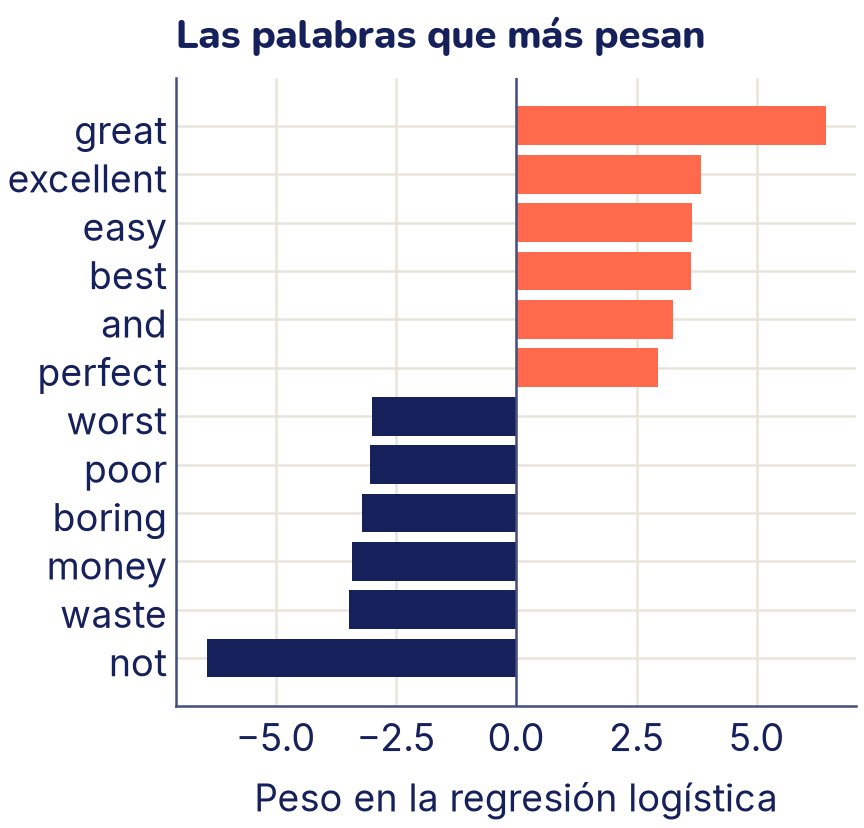

In [ ]:
pesos = modelo[1].coef_[0]
vocab_tfidf = modelo[0].get_feature_names_out()
orden = np.argsort(pesos)
elegidas = np.concatenate([orden[:6], orden[-6:]])
print("Más negativas:", list(vocab_tfidf[orden[:6]]))
print("Más positivas:", list(vocab_tfidf[orden[-6:][::-1]]))

# Tinta para las negativas y coral para las positivas
colores = ["C0"] * 6 + ["C1"] * 6
# Una figura más alta, para que las 12 palabras no se encimen
plt.figure(figsize=(4.8, 4.6))
plt.barh(range(12), pesos[elegidas], color=colores)
plt.yticks(range(12), vocab_tfidf[elegidas])
plt.axvline(0, color="C2", linewidth=1)
plt.xlabel("Peso en la regresión logística")
plt.title("Las palabras que más pesan")
plt.show()

Las palabras están en inglés porque las reseñas lo están: el modelo solo puede aprender pesos para las palabras que vio. *Great* (genial), *excellent* (excelente), *best* (lo mejor) y *perfect* (perfecto) empujan hacia positiva; *waste* (desperdicio), *boring* (aburrido), *poor* (malo) y *worst* (lo peor) hacia negativa. *Money* aparece por frases como *waste of money* (plata tirada). *Not* (no) es la más negativa de todas: las quejas suelen negar («*not* worth it», «does *not* work»). Pero ojo: en una bolsa de palabras, «not bad» (nada mal) también suma el peso negativo de *not*. Y *and* (y), que no significa nada bueno ni malo, recibe un peso positivo: el modelo no entiende significados, solo encontró que en estas reseñas esa palabra ayuda a separar las clases.

¿Qué pasa con textos nuevos?

In [ ]:
nuevas = ["Great book, I loved every page.",
          "It broke after two days. Waste of money.",
          "Me encantó, es un libro excelente."]
for texto, p in zip(nuevas, modelo.predict_proba(nuevas)[:, 1]):
    # .nnz cuenta los valores que no son cero: las palabras conocidas
    conocidas = modelo[0].transform([texto]).nnz
    print(f"P(positiva) = {p:.2f}   conocidas: {conocidas:>2}   {texto}")

P(positiva) = 0.96   conocidas:  5   Great book, I loved every page.
P(positiva) = 0.03   conocidas:  8   It broke after two days. Waste of money.
P(positiva) = 0.43   conocidas:  3   Me encantó, es un libro excelente.


Las dos reseñas en inglés se clasifican bien y con seguridad. La reseña en español es claramente positiva, pero el modelo solo reconoce 3 de sus palabras y responde 0,43, cerca del 50 %: no tiene idea. Un clasificador de bolsa de palabras solo sabe del idioma y del vocabulario con que se entrenó. Para clasificar en español habría que entrenarlo con reseñas en español; en el tema 25 verás modelos preentrenados que llegan con más idioma aprendido.

## Lotes de largo variable: *padding* y máscara

TF-IDF convierte cada texto en un vector del mismo largo, pero pierde el orden. Las redes neuronales de los temas que siguen leen el texto **en orden**, como una secuencia de IDs. Y en PyTorch se entrena por lotes (tema 18): un lote es un tensor, y un tensor tiene que ser rectangular. Si las frases tienen largos distintos, no se pueden apilar:

*La celda que sigue da un error a propósito: es parte de la explicación.*

In [ ]:
import torch
from torch.nn.utils.rnn import pad_sequence

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"

lote_frases = ["En un lugar de la Mancha",
               "Sancho comió pan",
               "Don Quijote vio molinos de viento"]
secuencias = [torch.tensor(codificar(palabras(f), vocab))
              for f in lote_frases]
print([len(s) for s in secuencias])
torch.stack(secuencias)

[6, 3, 6]
Traceback (most recent call last):
  ...
RuntimeError: stack expects each tensor to be equal size, but got [6] at entry 0 and [3] at entry 1


La solución es el ***padding*** (relleno): alargar las secuencias cortas con un token de relleno, `<PAD>`, hasta el largo de la más larga. Por eso reservamos el ID 0 para él. `pad_sequence` de PyTorch lo hace por nosotros. Además se arma una **máscara**: un tensor del mismo tamaño con 1 (o `True`) donde hay un token real y 0 donde hay relleno, para que el modelo sepa qué posiciones ignorar.

In [ ]:
lote = pad_sequence(secuencias, batch_first=True,
                    padding_value=vocab["<PAD>"]).to(device)
mascara = lote != vocab["<PAD>"]
print(lote.shape)
print(lote.tolist())
print(mascara.int().tolist())

torch.Size([3, 6])
[[7, 28, 122, 3, 5, 223], [23, 6350, 588, 0, 0, 0], [18, 22, 166, 2290, 3, 816]]
[[1, 1, 1, 1, 1, 1], [1, 1, 1, 0, 0, 0], [1, 1, 1, 1, 1, 1]]


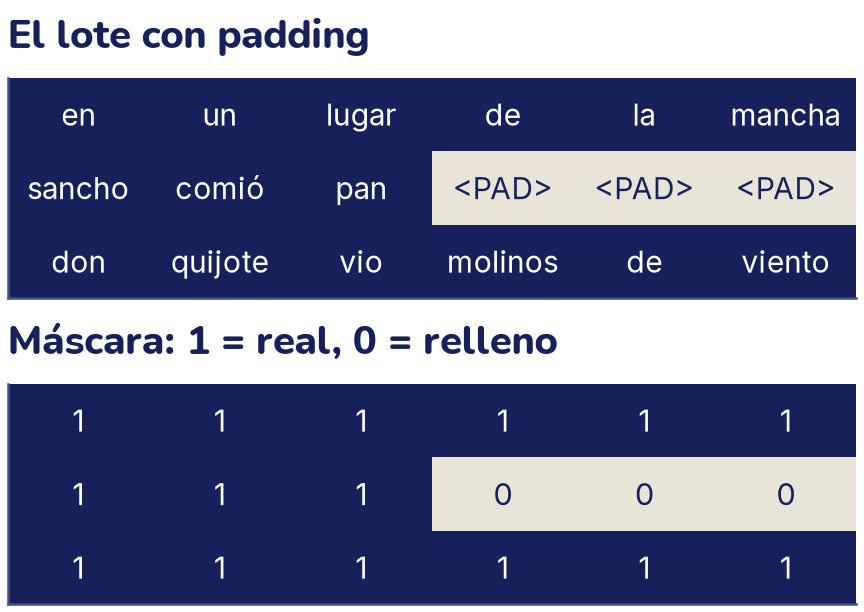

In [ ]:
# Solo para dibujar: el lote y la máscara como dos tablas
from matplotlib.colors import ListedColormap

inverso = {i: p for p, i in vocab.items()}
# Papel para el relleno y tinta para los tokens reales
papel_tinta = ListedColormap(["C3", "C0"])
fig, (arriba, abajo) = plt.subplots(2, 1)
for eje, valores in [(arriba, lote), (abajo, mascara.int())]:
    eje.imshow(mascara.cpu(), cmap=papel_tinta, aspect="auto")
    for i in range(lote.shape[0]):
        for j in range(lote.shape[1]):
            v = valores[i, j].item()
            txt = inverso[v] if eje is arriba else str(v)
            eje.text(j, i, txt, ha="center", va="center", fontsize=12,
                     color="white" if mascara[i, j] else "C0")
    eje.set_xticks([])
    eje.set_yticks([])
    eje.grid(False)
arriba.set_title("El lote con padding")
abajo.set_title("Máscara: 1 = real, 0 = relleno")
plt.show()

El lote tiene forma (3, 6): 3 frases de 6 tokens. La máscara es lo que permite, por ejemplo, promediar solo los tokens reales (tema 22) o que la atención no mire el relleno (tema 23). Si una frase es demasiado larga, se hace lo contrario: se **trunca**, cortándola en un largo máximo.

Los tokenizadores de Hugging Face hacen todo esto de una vez. Con `padding=True` rellenan, con `truncation=True` y `max_length` truncan, y devuelven la máscara con el nombre `attention_mask`:

In [ ]:
x_bert = tok_bert(lote_frases, padding=True, truncation=True,
                  max_length=8, return_tensors="pt")
print(x_bert["input_ids"].shape)
for fila, mask in zip(x_bert["input_ids"], x_bert["attention_mask"]):
    print(" ".join(tok_bert.convert_ids_to_tokens(fila)))
    print(mask.tolist())

torch.Size([3, 8])
[CLS] en un lu ##gar de la [SEP]
[1, 1, 1, 1, 1, 1, 1, 1]
[CLS] san ##cho com ##io pan [SEP] [PAD]
[1, 1, 1, 1, 1, 1, 1, 0]
[CLS] don qui ##jo ##te vi ##o [SEP]
[1, 1, 1, 1, 1, 1, 1, 1]


DistilBERT agrega sus tokens especiales: `[CLS]` al principio, `[SEP]` al final y `[PAD]` como relleno. Con `max_length=8`, la primera y la tercera frase se truncaron (se perdieron «mancha» y el final de la tercera), y la segunda recibió un relleno, marcado con 0 en su máscara.

## Lo que aprendiste y lo que sigue

- **Tokenizar** es partir el texto en pedazos. Por **palabras**, las secuencias son cortas pero el vocabulario es enorme y las palabras nuevas se pierden como `<UNK>`. Por **caracteres**, nunca hay desconocidos pero las secuencias son largas. **BPE** junta los pares más frecuentes y queda en el medio: más fusiones, menos tokens y más vocabulario.
- **Normalizar** (minúsculas, tildes, puntuación) es una decisión: en español, quitar las tildes confunde palabras distintas.
- La **ley de Zipf**: pocas palabras llenan la mayor parte del texto y casi la mitad del vocabulario aparece una sola vez.
- Un **modelo de lenguaje** da probabilidades a la palabra siguiente. Los **n-gramas** las estiman contando, y la **perplejidad** mide qué tan sorprendido queda el modelo con texto nuevo.
- **Naive Bayes** aplica la regla de Bayes suponiendo que las palabras son independientes dentro de cada clase: basta contar, sumar 1 (**suavizado de Laplace**) y sumar logaritmos. Es una buena línea base.
- La **bolsa de palabras** y **TF-IDF** convierten cada texto en un vector del mismo largo, y con regresión logística clasifican reseñas con 85 % de exactitud. Los pesos se pueden leer, y solo valen para el idioma con que se entrenó.
- Para pasar secuencias a una red, se rellenan con ***padding*** hasta el mismo largo y se acompañan de una **máscara**.

En el tema 22 los IDs dejan de ser simples números: cada token se convierte en un vector aprendido, un **embedding**, donde las palabras parecidas quedan cerca.

# Ejercicios

## Antes de empezar

Varios ejercicios usan las variables y funciones de la teoría: `quijote`, `todas`, `conteo`, `palabras`, `sin_tildes`, `construir_vocabulario`, `entrenar_bpe`, `tokenizar_bpe`, `tok_gpt2`, `contar_ngramas`, `cuentas`, `perplejidad`, `valid`, `mini`, `y_mini`, `cv_mini`, `X_mini`, `nueva`, `entrenar_nb`, `textos`, `etiquetas`, `X_ent`, `X_pru`, `y_ent`, `y_pru`, `X_sub`, `X_val`, `y_sub`, `y_val`, `candidatos` y `resenas`. En este cuaderno, ejecuta las celdas de la teoría y trabaja en los ejercicios, que vienen debajo. Intenta cada ejercicio antes de abrir la respuesta: equivocarse primero y corregir después es como se aprende de verdad.

## Ejercicios

### 1. ¿Qué normalizar?

Para cada caso, decide si conviene pasar a minúsculas, quitar las tildes y quitar la puntuación, y explica por qué:

1. Un buscador de recetas donde la gente escribe rápido desde el celular («receta de pique macho sin cebolla»).
2. Un modelo que corrige la ortografía de tareas escolares.
3. Un clasificador que decide si un mensaje es una pregunta o una afirmación.
4. Un contador de cuántas veces se nombra a cada personaje en el Quijote.

<details>
<summary>Respuesta</summary>

1. **Minúsculas sí, tildes fuera, puntuación fuera.** La gente escribe sin tildes desde el celular; para encontrar «limón» tiene que servir «limon». Aquí juntar variantes importa más que distinguir «él» de «el».
2. **Nada.** Las mayúsculas, las tildes y la puntuación son justamente lo que se corrige: si las quitas, el modelo no puede ver los errores.
3. **La puntuación se queda.** Los signos «¿» y «?» son la mejor pista. Las minúsculas no molestan.
4. **Minúsculas no.** «Sancho» con mayúscula es el personaje; las tildes pueden quedarse. Pero cuidado: al principio de una oración cualquier palabra va con mayúscula, así que también hay que mirar el contexto.

No hay una normalización correcta para todo: se elige según la tarea.

</details>

### 2. BPE a mano, con 5 fusiones

Entrena BPE a mano con este texto de cinco palabras: «sol sola solo sol solos». Empieza partiendo cada palabra en letras con «_» al final, cuenta los pares de piezas vecinas (cada palabra cuenta tantas veces como aparece) y haz 5 fusiones. Si hay empate, gana el par que aparece primero leyendo las palabras en orden, de izquierda a derecha. Al final, ¿en qué tokens queda partida cada palabra? Después compruébalo con `entrenar_bpe`.

<details>
<summary>Respuesta</summary>

Las palabras distintas son *sol* (2 veces), *sola*, *solo* y *solos* (1 vez cada una).

1. Los pares «s o» y «o l» aparecen 5 veces cada uno (en todas las palabras). Empate: gana «s o», que aparece primero. Nueva pieza: **so**.
2. Ahora «so l» aparece 5 veces. Nueva pieza: **sol**.
3. «sol _» aparece 2 veces (las dos de *sol*) y «sol o» también 2 (*solo* y *solos*). Empate: gana «sol _», porque *sol* es la primera palabra. Nueva pieza: **sol_**.
4. «sol o» es el único par con 2. Nueva pieza: **solo**.
5. Todos los pares que quedan aparecen 1 vez; el primero es «sol a», de *sola*. Nueva pieza: **sola**.

Resultado: *sol* = sol_, *sola* = sola + _, *solo* = solo + _, *solos* = solo + s + _.

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
fus, _ = entrenar_bpe(Counter("sol sola solo sol solos".split()), 5)
print(["".join(par) for par in fus])
for p in ["sol", "sola", "solo", "solos"]:
    print(p, tokenizar_bpe(p, fus))

### 3. ¿Cuántas palabras raras dejar fuera?

Usa el primer 80 % del Quijote para construir el vocabulario y el 10 % siguiente (la validación de la teoría) para medirlo; la prueba no se toca para elegir. Con `minimo` igual a 1, 2, 5 y 20, calcula el tamaño del vocabulario y qué porcentaje de las palabras de la validación quedan como `<UNK>`. ¿Qué gana y qué pierde un vocabulario chico?

In [ ]:
# @title Respuesta: código (doble clic para verlo)
corte_ent = int(0.8 * len(todas))
corte_val = int(0.9 * len(todas))
conteo_ent = Counter(todas[:corte_ent])
validacion = todas[corte_ent:corte_val]
for minimo in [1, 2, 5, 20]:
    v = construir_vocabulario(conteo_ent, minimo)
    unk = sum(p not in v for p in validacion) / len(validacion)
    print(f"mínimo {minimo:>2}: vocabulario {len(v):>6,}   "
          f"desconocidas en la validación: {unk:.1%}")

<details>
<summary>Respuesta</summary>

Con `minimo=1` (todas las palabras del entrenamiento) el vocabulario casi se duplica respecto de `minimo=2` (20 379 contra 10 208), pero las desconocidas solo bajan de 6,3 % a 4,0 %: casi todas las palabras que aparecen una sola vez en el entrenamiento no vuelven a aparecer en la validación. Con `minimo=20`, el vocabulario es muy chico (un modelo más liviano, con menos que aprender), pero casi una de cada cinco palabras de la validación se pierde como `<UNK>`. Por eso los modelos modernos usan subpalabras: con BPE no hay que tirar ninguna palabra.

</details>

### 4. Perplejidad con n = 1, 2 y 3

Calcula la perplejidad del modelo de la teoría sobre la validación con *n* = 1, 2 y 3, primero con `lam=0.6` y después con `lam=0.3`. ¿El trigrama es mejor que el bigrama? ¿Por qué crees que pasa eso?

In [ ]:
# @title Respuesta: código (doble clic para verlo)
for lam in [0.6, 0.3]:
    resultado = [perplejidad(valid, n, lam) for n in (1, 2, 3)]
    print(f"lam = {lam}:  " + "   ".join(
        f"n = {n}: {p:.0f}" for n, p in zip((1, 2, 3), resultado)))

trigramas, _ = cuentas[3]
nuevos = sum(tuple(valid[i:i + 3]) not in trigramas
             for i in range(len(valid) - 2))
print(f"Trigramas de la validación nunca vistos: "
      f"{nuevos / (len(valid) - 2):.0%}")

<details>
<summary>Respuesta</summary>

El unigrama no usa `lam`, así que da lo mismo en las dos filas. El bigrama mejora mucho al unigrama. El trigrama, en cambio, **empeora** con `lam=0.6` (269 contra 210), y con `lam=0.3` llega a 216, todavía un poco peor que el mejor bigrama. Por eso en la teoría nos quedamos con el bigrama y `lam=0.6` antes de mirar la prueba. La razón está en la última línea: la mayoría de los trigramas de la validación nunca aparecieron en el entrenamiento. Un solo libro no alcanza para estimar bien tantas combinaciones de tres palabras, y confiar mucho en esas cuentas (un `lam` alto) castiga al modelo. Más contexto solo ayuda si hay datos para aprenderlo; los modelos neuronales del tema 24 lo logran porque comparten lo aprendido entre palabras parecidas.

</details>

### 5. La bolsa no ve el orden

Estas dos reseñas dicen lo contrario: «no es bueno, es malo» y «no es malo, es bueno». Calcula su bolsa de palabras con `CountVectorizer()`. ¿Son distintas? Repite con `CountVectorizer(ngram_range=(1, 2))`, que además de las palabras cuenta los **bigramas** (pares de palabras seguidas).

In [ ]:
# @title Respuesta: código (doble clic para verlo)
dos = ["no es bueno, es malo", "no es malo, es bueno"]
for rango in [(1, 1), (1, 2)]:
    cv = CountVectorizer(ngram_range=rango)
    X2 = cv.fit_transform(dos).toarray()
    print(rango, "¿iguales?", (X2[0] == X2[1]).all())
print(list(cv.get_feature_names_out()))

<details>
<summary>Respuesta</summary>

Con palabras sueltas, las dos reseñas son el **mismo vector**: ningún modelo podría separarlas. Con bigramas aparecen «no es», «es bueno» y «es malo», y ahora sí son distintas: «bueno es» solo está en la primera y «malo es» solo en la segunda. Los bigramas recuperan un poco de orden, a cambio de un vocabulario mucho más grande.

</details>

### 6. Bigramas en el clasificador

Compara el clasificador de reseñas de la teoría (solo palabras) con uno que use `TfidfVectorizer(min_df=2, ngram_range=(1, 2))`: tamaño del vocabulario y exactitud. Para comparar no uses la prueba: entrena los dos con `X_sub` y mídelos en la validación `X_val`, como en la teoría. ¿Qué peso recibe el bigrama «not bad»?

In [ ]:
# @title Respuesta: código (doble clic para verlo)
for rango in [(1, 1), (1, 2)]:
    m = make_pipeline(TfidfVectorizer(min_df=2, ngram_range=rango),
                      LogisticRegression(max_iter=1000))
    m.fit(X_sub, y_sub)
    print(f"{rango}: vocabulario {len(m[0].vocabulary_):>6,}   "
          f"exactitud en la validación {m.score(X_val, y_val):.3f}")
# m quedó con el último modelo del bucle: el de bigramas
vocab_bi = m[0].vocabulary_
pesos_bi = m[1].coef_[0]
for frase in ["not", "not bad", "not good", "not worth"]:
    print(f"{frase:<10} {pesos_bi[vocab_bi[frase]]:+.2f}")

<details>
<summary>Respuesta</summary>

El vocabulario se multiplica casi por cuatro, pero la exactitud en la validación apenas sube (de 0,847 a 0,855): con 3840 reseñas de entrenamiento, la mayoría de los bigramas aparecen muy pocas veces para aprender bien su peso. Aun así, el modelo aprendió algo con sentido: «not bad» tiene peso positivo, al revés que «not» solo, y «not worth» (no vale la pena) es claramente negativo.

</details>

### 7. Formas con padding

Tienes tres secuencias de IDs de largos 4, 7 y 2. Sin computadora, responde: ¿qué forma tiene el lote que devuelve `pad_sequence(..., batch_first=True)`? ¿Cuántos ceros de relleno tiene? ¿Cuánto suma la máscara? ¿Y si después truncas el lote a 5 posiciones con `lote[:, :5]`? Compruébalo con código.

<details>
<summary>Respuesta</summary>

El lote tiene forma (3, 7): tres secuencias, rellenadas hasta 7, la más larga. Hay 3 + 0 + 5 = 8 ceros de relleno, y la máscara suma 4 + 7 + 2 = 13 (los tokens reales). Truncado a 5 queda (3, 5); la segunda secuencia pierde 2 tokens, y la máscara suma 4 + 5 + 2 = 11.

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
seqs = [torch.arange(1, n + 1) for n in [4, 7, 2]]
l = pad_sequence(seqs, batch_first=True)
m = l != 0
print(l.shape, "relleno:", (~m).sum().item(),
      " máscara:", m.sum().item())
print(l[:, :5].shape, "máscara:", m[:, :5].sum().item())

### 8. ¿Cuánto cuesta el español en GPT-2?

Cuenta cuántos tokens de GPT-2 hay por palabra en las primeras 2000 palabras del Quijote y en las primeras 2000 palabras de las reseñas (en inglés). ¿Cuántas veces más tokens necesita el español? Para comparar, haz lo mismo con el BPE de la teoría (300 fusiones).

In [ ]:
# @title Respuesta: código (doble clic para verlo)
texto_es = " ".join(quijote.split()[:2000])
texto_en = " ".join(" ".join(textos).split()[:2000])
for nombre, t in [("Quijote", texto_es), ("Reseñas", texto_en)]:
    n_pal = len(palabras(t))
    gpt2 = len(tok_gpt2.tokenize(t)) / n_pal
    nuestro = sum(len(tokenizar_bpe(p, fusiones))
                  for p in palabras(t)) / n_pal
    print(f"{nombre}: GPT-2 {gpt2:.2f}   nuestro BPE {nuestro:.2f}"
          "   tokens por palabra")

<details>
<summary>Respuesta</summary>

GPT-2 usa bastante más tokens por palabra en el español del Quijote que en las reseñas en inglés, y nuestro BPE hace lo contrario. (Los tokens de GPT-2 incluyen la puntuación, que `palabras` no cuenta, así que sus números salen un poco inflados en los dos idiomas.) Un modelo con un tokenizador entrenado en inglés lee menos texto en español con el mismo largo máximo, y le cuesta más tiempo procesarlo.

</details>

### 9. Sin suavizado

Con las seis opiniones del restaurante de la teoría, entrena `entrenar_nb` con `alpha=0`, es decir, sin suavizado. ¿Cuánto valen P(buena | negativa) y P(caro | positiva)? Calcula, **sin logaritmos**, el producto P(clase) · P(w₁ | clase) · P(w₂ | clase) · … de «buena comida pero caro» para cada clase. ¿Qué pasa? Después elige el `alpha` de `MultinomialNB` para las reseñas entre 0.01, 0.1, 1 y 3, con la validación. ¿Alguno le gana a la logística (0,847)?

In [ ]:
# @title Respuesta: código (doble clic para verlo)
prior0, log_p0 = entrenar_nb(X_mini, y_mini, alpha=0)
p0 = np.exp(log_p0)
voc = cv_mini.vocabulary_
print("P(buena | negativa) =", p0[0, voc["buena"]],
      "  P(caro | positiva) =", p0[1, voc["caro"]])
# Cada P(w | clase) elevada a las veces que w aparece en el texto
producto = np.exp(prior0) * np.prod(p0 ** nueva[0], axis=1)
print("Producto (negativa, positiva):", producto)

for a in [0.01, 0.1, 1, 3]:
    m = make_pipeline(CountVectorizer(min_df=2), MultinomialNB(alpha=a))
    m.fit(X_sub, y_sub)
    print(f"alpha = {a:<4}  exactitud en la validación "
          f"{m.score(X_val, y_val):.3f}")

<details>
<summary>Respuesta</summary>

(NumPy avisa `divide by zero encountered in log`: es el ln 0 = −∞ de las palabras que faltan en una clase.) «buena» nunca aparece en las negativas y «caro» nunca en las positivas, así que sin suavizado las dos probabilidades son 0, y **los dos productos dan 0**: el modelo no puede decidir, y queda una división 0/0. Una sola palabra ausente borra toda la demás evidencia del texto. Con las reseñas, un `alpha` muy chico es mucho peor (0,776 con 0.01): una palabra rara que solo apareció en una clase se vuelve casi una prueba definitiva. `alpha` = 1 y 3 quedan casi empatados (0,830 y 0,831), y ninguno alcanza a la logística.

</details>

### 10. ¿Qué tan ingenuo?

Calcula P(positiva) para «great», «great great» y «great great great great» con los dos modelos de `candidatos` (entrenados con `X_sub`). Antes de correrlo, predice: ¿qué le pasa a cada modelo cuando la palabra se repite? Calcula también P(great | positiva) / P(great | negativa) en Naive Bayes.

In [ ]:
# @title Respuesta: código (doble clic para verlo)
nb_res = candidatos["Naive Bayes"]
log_res = candidatos["Logística"]
for texto in ["great", "great great", "great great great great"]:
    p_nb = nb_res.predict_proba([texto])[0, 1]
    p_log = log_res.predict_proba([texto])[0, 1]
    print(f"{texto:<24} Naive Bayes {p_nb:.3f}   logística {p_log:.3f}")

lp = nb_res[1].feature_log_prob_
i = nb_res[0].vocabulary_["great"]
print(f"P(great | positiva) / P(great | negativa) = "
      f"{np.exp(lp[1, i] - lp[0, i]):.1f}")

<details>
<summary>Respuesta</summary>

En Naive Bayes, cada «great» cuenta como una evidencia nueva e independiente: multiplica por 3,6 la razón entre las dos clases, y la probabilidad sube de 0,78 a 0,93 y a 0,99 sin que el texto diga nada nuevo. Esa es la suposición ingenua en acción, y por eso las probabilidades de Naive Bayes suelen ser **demasiado seguras**: sirven para decidir la clase, pero no conviene creerles el número. La logística da lo mismo con las tres frases, porque TF-IDF divide cada fila por su norma y las tres quedan como el mismo vector. Eso no la hace más sabia: con una sola palabra, TF-IDF le da a «great» el valor 1, mucho más de lo que pesa dentro de una reseña normal, y por eso responde 0,997.

</details>

## Mini-proyecto: un clasificador de sentimiento y sus errores

Construye el mejor clasificador de reseñas que puedas con TF-IDF y regresión logística, y después **mira sus errores**: es la parte que más enseña.

1. Toma 20 000 reseñas de `resenas` (con `shuffle(seed=1)`, para que no sean las mismas de la teoría) y divídelas en entrenamiento (70 %), validación (15 %) y prueba (15 %), estratificando.
2. Elige con la validación la mejor combinación de `ngram_range` (`(1, 1)` o `(1, 2)`) y de `C` de la regresión logística (0.3, 1, 3 y 10; recuerda del tema 8 que un `C` más chico regulariza más).
3. Con la mejor combinación, entrena con entrenamiento y validación juntos, y mide **una sola vez** en la prueba: exactitud, precisión y exhaustividad (tema 9).
4. Busca los errores en los que el modelo estaba **más seguro**: las reseñas negativas con mayor probabilidad de ser positivas, y al revés. Léelas. ¿Por qué se equivocó? Busca negaciones, ironía, reseñas que hablan bien de una cosa y mal de otra, o etiquetas que parecen equivocadas.
5. Escribe tres o cuatro reseñas propias en inglés que creas que van a engañar al modelo, y comprueba si lo logras.

Opcional: escribe 20 reseñas cortas en español (10 positivas y 10 negativas), entrena un clasificador solo con ellas y pruébalo con otras 5. ¿Qué pasa con tan pocos datos?

<details>
<summary>Resultados de referencia, para comprobar los tuyos</summary>

Este código hace los pasos 1 a 4; tus números deberían coincidir si usas la misma semilla y la misma división.

</details>

In [ ]:
# @title Resultados de referencia, para comprobar los tuyos: código (doble clic para verlo)
from sklearn.metrics import precision_score, recall_score

datos = resenas.shuffle(seed=1).select(range(20000))
txt = np.array([f"{t}. {c}" for t, c in zip(datos["title"],
                                            datos["content"])])
lab = np.array(datos["label"])
txt_ent, txt_resto, lab_ent, lab_resto = train_test_split(
    txt, lab, test_size=0.3, random_state=0, stratify=lab)
txt_val, txt_pru, lab_val, lab_pru = train_test_split(
    txt_resto, lab_resto, test_size=0.5, random_state=0,
    stratify=lab_resto)

resultados = {}
for rango in [(1, 1), (1, 2)]:
    for C in [0.3, 1, 3, 10]:
        m = make_pipeline(TfidfVectorizer(min_df=2, ngram_range=rango),
                          LogisticRegression(C=C, max_iter=1000))
        resultados[rango, C] = m.fit(txt_ent, lab_ent).score(txt_val,
                                                             lab_val)
        print(f"{rango}  C = {C:<4} validación: "
              f"{resultados[rango, C]:.3f}")

rango, C = max(resultados, key=resultados.get)
final = make_pipeline(TfidfVectorizer(min_df=2, ngram_range=rango),
                      LogisticRegression(C=C, max_iter=1000))
final.fit(np.concatenate([txt_ent, txt_val]),
          np.concatenate([lab_ent, lab_val]))
pred = final.predict(txt_pru)
print(f"Elegido: {rango}, C = {C}")
print(f"Prueba: exactitud {(pred == lab_pru).mean():.3f}   "
      f"precisión {precision_score(lab_pru, pred):.3f}   "
      f"exhaustividad {recall_score(lab_pru, pred):.3f}")

In [ ]:
# @title Resultados de referencia, para comprobar los tuyos: código (doble clic para verlo)
p_pos = final.predict_proba(txt_pru)[:, 1]
negativas_altas = np.argsort(np.where(lab_pru == 0, p_pos, -1))[::-1]
positivas_bajas = np.argsort(np.where(lab_pru == 1, p_pos, 2))
for titulo, indices in [("Negativas que parecían positivas",
                         negativas_altas),
                        ("Positivas que parecían negativas",
                         positivas_bajas)]:
    print(titulo)
    # Saltamos las reseñas con insultos: son reales y algunas los tienen
    limpias = [i for i in indices
               if not set(palabras(txt_pru[i])) & {"stupid", "idiot",
                                                    "idiots", "dumb",
                                                    "crap", "hell",
                                                    "damn", "sucks"}]
    for i in limpias[:3]:
        print(f"  {p_pos[i]:.2f}  {txt_pru[i][:66]}")

<details>
<summary>Resultados de referencia, para comprobar los tuyos (sigue)</summary>

Con validación se eligió `(1, 2)` y `C = 10`, aunque las ocho combinaciones quedan a menos de 3 puntos entre sí. En la prueba, con 14 000 + 3000 reseñas para entrenar, la exactitud sube a 0,90: más datos ayudan más que afinar el modelo. Al leer los errores más seguros aparecen los casos típicos:

- Reseñas con palabras positivas que critican otra cosa: el título de la segunda dice *good* (bueno) y la tercera empieza diciendo que una película es de las mejores (*greatest*), pero las dos están marcadas como negativas.
- Reseñas positivas llenas de *not*: la primera y la tercera de la segunda lista niegan cosas («no es un libro», «no dejes que el título te engañe») para defender el producto.
- Etiquetas que parecen equivocadas: la primera de la lista de arriba suena a una reseña contenta. En un dataset real siempre hay algo de ruido en las etiquetas.

Una bolsa de palabras no puede entender a qué se refiere cada palabra ni el tono de la frase; para eso hacen falta los modelos que leen el texto en orden, desde el tema 23.

</details>

## Errores comunes

- **Normalizar sin pensar.** Quitar tildes, mayúsculas o puntuación a todo es una decisión que puede borrar justo la información que importa («él» y «el», o el «¿» de una pregunta).
- **Construir el vocabulario con todos los datos.** El vocabulario, los IDF y cualquier conteo se aprenden **solo con el entrenamiento**; si no, hay fuga de datos (tema 10). Un `Pipeline` lo hace bien solo.
- **Llamar `fit_transform` en la prueba.** En la prueba va `transform`: con `fit_transform` el vectorizador aprende otro vocabulario y las columnas ya no significan lo mismo que en el entrenamiento.
- **Olvidar `<UNK>`.** Si el vocabulario no tiene un token para lo desconocido, la primera palabra nueva hace fallar el código con un `KeyError`.
- **Usar como ID de relleno un número que también es un token real.** Si `<PAD>` y una palabra comparten el 0, la máscara borra esa palabra. Reserva un ID solo para el relleno.
- **Rellenar y olvidar la máscara.** Sin máscara, el modelo trata el relleno como si fueran palabras: un promedio de la frase sale distinto según cuánto relleno tenga.
- **Mezclar tokenizadores.** Los IDs de un tokenizador solo tienen sentido para el modelo que se entrenó con él: el 2000 de GPT-2 no es el 2000 de DistilBERT.
- **Creer que un peso grande es una regla del idioma.** «and» con peso positivo no significa que «y» sea una palabra alegre: el modelo encuentra correlaciones en sus datos, no significados.
- **Usar un modelo en un idioma distinto del de su entrenamiento.** Un clasificador entrenado con reseñas en inglés no sabe nada de una reseña en español: casi todas sus palabras le son desconocidas.
- **Olvidar el suavizado en Naive Bayes.** Sin sumar 1 a las cuentas, una sola palabra que nunca apareció en una clase pone en 0 la probabilidad de esa clase, por más que el resto del texto la apoye.
- **Multiplicar probabilidades sin logaritmos.** Con textos largos, el producto de cientos de probabilidades pequeñas se redondea a 0; se suman sus logaritmos.
- **Comparar perplejidades con vocabularios distintos.** La perplejidad depende del vocabulario y de cómo se tratan los desconocidos; solo se comparan modelos medidos sobre el mismo texto y con el mismo vocabulario.

## ¿Lo lograste?

Al terminar este tema deberías poder hacer lo siguiente. Al lado, dónde lo practicaste.

- Normalizar un texto en español y decidir qué conservar (ejercicio 1).
- Tokenizar por palabras, por caracteres y por subpalabras con BPE (actividad, ejercicio 2 y ejercicio 8).
- Construir un vocabulario con un token desconocido y elegir su tamaño (ejercicio 3).
- Representar textos con bolsa de palabras y TF-IDF y clasificarlos con regresión logística (ejercicios 5 y 6, y el mini-proyecto).
- Aplicar *padding*, truncado y máscaras a secuencias de largo variable (ejercicio 7).
- Construir un modelo de lenguaje de n-gramas y medir su perplejidad (ejercicio 4).
- Programar Naive Bayes con conteos y logaritmos, y compararlo con la regresión logística en la validación (ejercicios 9 y 10).